# Explaining GoogLeNet Flower Predictions

I explored how a vision classifier uses color channels, intermediate features, and image regions in my Deep Learning coursework. This notebook compares RGB permutation, feature-channel ablation, occlusion sensitivity, and SHAP expected-gradient attributions on Oxford Flowers102.

I keep official training, validation, and test partitions separate. Validation loss selects the checkpoint; the test split is evaluated after training. Five deliberately selected examples (four correct and one incorrect) illustrate explanations and are not a representative accuracy sample.

In [1]:
import random,time,copy,json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets,transforms,models
from torchvision.models import GoogLeNet_Weights
from sklearn.metrics import accuracy_score,f1_score
from scipy.stats import spearmanr
import shap
from IPython.display import display
SEED=42
random.seed(SEED);np.random.seed(SEED);torch.manual_seed(SEED)
torch.set_num_threads(2)
assert torch.cuda.is_available(),'This training run requires a GPU.'
torch.cuda.manual_seed_all(SEED);device=torch.device('cuda')
print('PyTorch:',torch.__version__,'SHAP:',shap.__version__,'GPU:',torch.cuda.get_device_name(0))

plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':0.18,'font.size':10})
def diagram(labels,title):
 fig,ax=plt.subplots(figsize=(12,2.8));ax.axis('off')
 for i,label in enumerate(labels):
  x=(i+.5)/len(labels);ax.text(x,.5,label,ha='center',va='center',transform=ax.transAxes,bbox={'boxstyle':'round,pad=0.6','facecolor':'#e8f0fe','edgecolor':'#2563eb'},fontsize=9)
  if i<len(labels)-1:ax.annotate('',xy=((i+1.2)/len(labels),.5),xytext=((i+.8)/len(labels),.5),xycoords='axes fraction',arrowprops={'arrowstyle':'->','color':'#2563eb'})
 ax.set_title(title,pad=20);plt.tight_layout();plt.show()

PyTorch: 2.11.0+cu128 SHAP: 0.52.0 GPU: Tesla T4


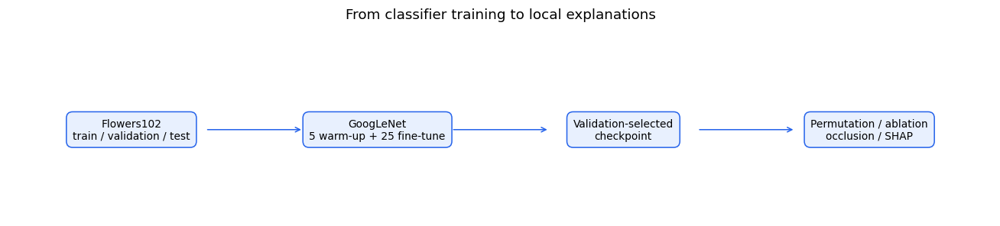

In [2]:
diagram(['Flowers102\ntrain / validation / test','GoogLeNet\n5 warm-up + 25 fine-tune','Validation-selected\ncheckpoint','Permutation / ablation\nocclusion / SHAP'],'From classifier training to local explanations')

## Data and evaluation design

The official splits contain 1,020 training, 1,020 validation, and 6,149 test images across 102 classes. Training uses spatial and color augmentation; validation and explanation images use deterministic resizing and cropping. All tensors use ImageNet normalization.

The pretrained weights and benchmark split files are verified before use. Training images provide the SHAP background distribution. The test images never select the checkpoint.

In [3]:
# Build the torchvision layout from attached images and verified benchmark metadata.
from pathlib import Path
import shutil, hashlib
base = Path('/tmp/coursework-data/flowers-102')
base.mkdir(parents=True, exist_ok=True)
image_matches = list(Path('/kaggle/input').rglob('image_00001.jpg'))
if len(image_matches) != 1:
    raise RuntimeError(f'Expected one Flowers102 image collection; found {len(image_matches)}')
images = image_matches[0].parent
if len(list(images.glob('image_*.jpg'))) != 8189:
    raise RuntimeError('The Flowers102 image collection is incomplete.')
if not (base/'jpg').exists():
    (base/'jpg').symlink_to(images, target_is_directory=True)
checksums = {'imagelabels.mat':'e0620be6f572b9609742df49c70aed4d',
             'setid.mat':'a5357ecc9cb78c4bef273ce3793fc85c'}
for filename, checksum in checksums.items():
    matches = [p for p in Path('/kaggle/input').rglob(filename)
               if hashlib.md5(p.read_bytes()).hexdigest() == checksum]
    if not matches:
        raise RuntimeError(f'Missing verified Flowers102 metadata: {filename}')
    shutil.copy2(matches[0], base/filename)
weights = next(Path('/kaggle/input').rglob('googlenet-1378be20.pth'))
if not hashlib.sha256(weights.read_bytes()).hexdigest().startswith('1378be20'):
    raise RuntimeError('Pretrained weight checksum mismatch.')
weight_cache = Path(torch.hub.get_dir())/'checkpoints'
weight_cache.mkdir(parents=True, exist_ok=True)
shutil.copy2(weights, weight_cache/weights.name)

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

# ── Augmented transform for TRAINING ──────────────────────────────────────
transform_train = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.7, 1.0)),   # random crop
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(30),
    transforms.ColorJitter(brightness=0.3, contrast=0.3,
                           saturation=0.3, hue=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

# ── Clean transform for VAL / TEST / XAI ──────────────────────────────────
transform_eval = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

def denormalize(t):
    m = torch.tensor(IMAGENET_MEAN).view(3,1,1)
    s = torch.tensor(IMAGENET_STD).view(3,1,1)
    return (t * s + m).clamp(0, 1)

{'training': 1020, 'validation': 1020, 'test': 6149}


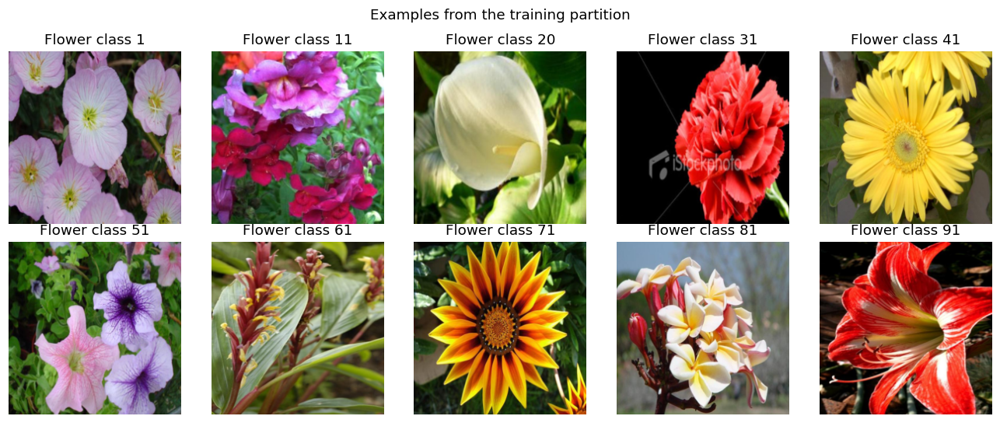

In [4]:
NUM_CLASSES=102
DATA_DIR='/tmp/coursework-data'
train_aug=datasets.Flowers102(DATA_DIR,split='train',download=False,transform=transform_train)
train_clean=datasets.Flowers102(DATA_DIR,split='train',download=False,transform=transform_eval)
val_clean=datasets.Flowers102(DATA_DIR,split='val',download=False,transform=transform_eval)
test_full=datasets.Flowers102(DATA_DIR,split='test',download=False,transform=transform_eval)
train_loader=DataLoader(train_aug,batch_size=32,shuffle=True,num_workers=0)
val_loader=DataLoader(val_clean,batch_size=32,shuffle=False,num_workers=0)
test_loader=DataLoader(test_full,batch_size=32,shuffle=False,num_workers=0)
print({'training':len(train_aug),'validation':len(val_clean),'test':len(test_full)})
fig,axes=plt.subplots(2,5,figsize=(12,5))
for i,ax in enumerate(axes.flat):
 image,label=train_clean[i*100];ax.imshow(denormalize(image).permute(1,2,0));ax.set_title(f'Flower class {label+1}');ax.axis('off')
fig.suptitle('Examples from the training partition');plt.tight_layout();plt.show()

## Warm-up and fine-tuning

I train the three classifier heads for five epochs, then unfreeze the model for 25 further epochs. The warm-up freezes backbone parameters and batch-normalization running statistics. Auxiliary classifier branches are randomly initialized by torchvision; their hidden layers are fixed during warm-up and train during fine-tuning.

Fine-tuning uses mixup (α = 0.4), label smoothing (0.1), and cosine learning-rate decay. The mixup accuracy below weights correctness against both mixed labels; it is a training diagnostic, not accuracy on natural images. Training objective includes auxiliary losses; validation loss uses the main classifier only.

In [5]:
def build_googlenet(nc=102):
    m = models.googlenet(weights=GoogLeNet_Weights.DEFAULT, aux_logits=True)
    m.fc       = nn.Linear(m.fc.in_features, nc)
    m.aux1.fc2 = nn.Linear(m.aux1.fc2.in_features, nc)
    m.aux2.fc2 = nn.Linear(m.aux2.fc2.in_features, nc)
    return m

def freeze_backbone(model):
    """Freeze all layers except the three classifier heads."""
    for p in model.parameters(): p.requires_grad = False
    for p in model.fc.parameters():       p.requires_grad = True
    for p in model.aux1.fc2.parameters(): p.requires_grad = True
    for p in model.aux2.fc2.parameters(): p.requires_grad = True

def unfreeze_all(model):
    """Unfreeze every parameter."""
    for p in model.parameters(): p.requires_grad = True

def count_trainable(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

print('Model builder defined.')
def mixup_batch(x, y, alpha=0.4):
    """Apply Mixup augmentation to a batch."""
    if alpha <= 0: return x, y, y, 1.0
    lam = np.random.beta(alpha, alpha)
    idx = torch.randperm(x.size(0), device=x.device)
    x_mix  = lam * x + (1 - lam) * x[idx]
    y_a, y_b = y, y[idx]
    return x_mix, y_a, y_b, lam

def mixup_loss(criterion, logits, y_a, y_b, lam):
    return lam * criterion(logits, y_a) + (1 - lam) * criterion(logits, y_b)

print('Mixup utilities defined.')

Model builder defined.
Mixup utilities defined.


In [6]:
def run_epoch(model, loader, criterion, optimizer=None, use_mixup=False):
    training = optimizer is not None
    model.train() if training else model.eval()
    if training and getattr(model,'freeze_statistics',False):
        for layer in model.modules():
            if isinstance(layer,nn.BatchNorm2d):layer.eval()
    ls, correct, total = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            if training: optimizer.zero_grad()
            # Mixup only during training
            if training and use_mixup:
                inputs, y_a, y_b, lam = mixup_batch(inputs, labels)
            outs = model(inputs)
            if training:
                logits = outs.logits
                if use_mixup:
                    loss = mixup_loss(criterion, logits, y_a, y_b, lam)
                    if outs.aux_logits1 is not None:
                        loss += 0.3 * mixup_loss(criterion, outs.aux_logits1, y_a, y_b, lam)
                    if outs.aux_logits2 is not None:
                        loss += 0.3 * mixup_loss(criterion, outs.aux_logits2, y_a, y_b, lam)
                else:
                    loss = criterion(logits, labels)
                    if outs.aux_logits1 is not None: loss += 0.3 * criterion(outs.aux_logits1, labels)
                    if outs.aux_logits2 is not None: loss += 0.3 * criterion(outs.aux_logits2, labels)
                loss.backward(); optimizer.step()
            else:
                logits = outs
                loss = criterion(logits, labels)
            ls      += loss.item() * labels.size(0)
            # For accuracy, use original labels (not mixed)
            preds    = logits.argmax(1)
            ref_lbl  = labels
            if training and use_mixup:
                correct += (lam*(preds==y_a).float()+(1-lam)*(preds==y_b).float()).sum().item()
            else:correct += (preds == ref_lbl).sum().item()
            total   += labels.size(0)
    return ls / total, correct / total

print('Training utilities ready.')

Training utilities ready.


/usr/local/lib/python3.13/dist-packages/torchvision/models/googlenet.py:341: UserWarning: auxiliary heads in the pretrained googlenet model are NOT pretrained, so make sure to train them
  warnings.warn(


Epoch 01/30 | training objective 7.4545 | validation loss 4.1092 | validation accuracy 25.10%


Epoch 02/30 | training objective 6.6091 | validation loss 3.5553 | validation accuracy 43.14%


Epoch 03/30 | training objective 6.0343 | validation loss 3.1714 | validation accuracy 55.88%


Epoch 04/30 | training objective 5.5969 | validation loss 2.8663 | validation accuracy 63.14%


...

Epoch 28/30 | training objective 3.6135 | validation loss 1.5088 | validation accuracy 86.18%


Epoch 29/30 | training objective 3.8020 | validation loss 1.5252 | validation accuracy 85.88%


Epoch 30/30 | training objective 3.7002 | validation loss 1.4874 | validation accuracy 86.86%


Selected epoch: 30


,epoch,training_objective,training_accuracy_diagnostic,validation_loss,validation_accuracy,learning_rate
25,26,3.916488,0.769980,1.523608,0.857843,0.000010
26,27,3.644755,0.822596,1.504197,0.866667,0.000007
27,28,3.613490,0.821165,1.508835,0.861765,0.000004
28,29,3.801987,0.781952,1.525217,0.858824,0.000003
29,30,3.700171,0.803080,1.487435,0.868627,0.000001


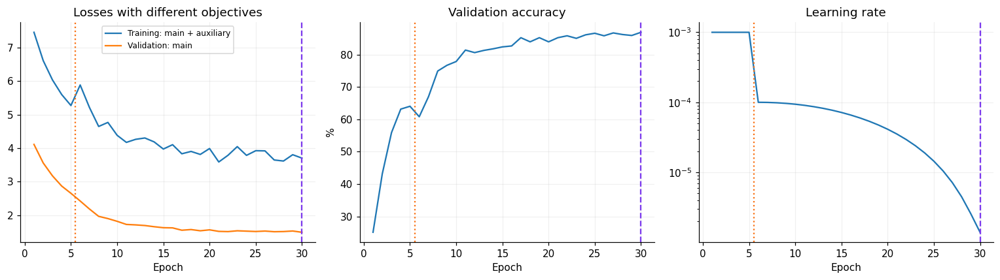

In [7]:
WARMUP_EPOCHS=5;FINETUNE_EPOCHS=25
model=build_googlenet(NUM_CLASSES).to(device)
criterion=nn.CrossEntropyLoss(label_smoothing=.1)
freeze_backbone(model);model.freeze_statistics=True
optimizer=optim.Adam(filter(lambda p:p.requires_grad,model.parameters()),lr=1e-3)
best_loss=float('inf');best_state=None;best_epoch=None;history=[]
start=time.perf_counter()
for epoch in range(1,31):
 if epoch==6:
  unfreeze_all(model);model.freeze_statistics=False
  optimizer=optim.Adam(model.parameters(),lr=1e-4,weight_decay=1e-4)
  scheduler=optim.lr_scheduler.CosineAnnealingLR(optimizer,T_max=25,eta_min=1e-6)
 lr=optimizer.param_groups[0]['lr']
 tl,ta=run_epoch(model,train_loader,criterion,optimizer,use_mixup=epoch>5)
 vl,va=run_epoch(model,val_loader,criterion)
 history.append({'epoch':epoch,'training_objective':tl,'training_accuracy_diagnostic':ta,'validation_loss':vl,'validation_accuracy':va,'learning_rate':lr})
 if vl<best_loss:best_loss=vl;best_epoch=epoch;best_state=copy.deepcopy(model.state_dict())
 if epoch>5:scheduler.step()
 print(f'Epoch {epoch:02d}/30 | training objective {tl:.4f} | validation loss {vl:.4f} | validation accuracy {va:.2%}',flush=True)
training_seconds=time.perf_counter()-start
model.load_state_dict(best_state);model.eval()
history=pd.DataFrame(history);print('Selected epoch:',best_epoch)
display(history.tail())
fig,axes=plt.subplots(1,3,figsize=(14,4))
axes[0].plot(history.epoch,history.training_objective,label='Training: main + auxiliary');axes[0].plot(history.epoch,history.validation_loss,label='Validation: main');axes[0].set(title='Losses with different objectives',xlabel='Epoch');axes[0].legend(fontsize=8)
axes[1].plot(history.epoch,history.validation_accuracy*100);axes[1].set(title='Validation accuracy',xlabel='Epoch',ylabel='%')
axes[2].semilogy(history.epoch,history.learning_rate);axes[2].set(title='Learning rate',xlabel='Epoch')
for ax in axes:ax.axvline(5.5,color='#f97316',ls=':',label='Unfreeze');ax.axvline(best_epoch,color='#7c3aed',ls='--')
plt.tight_layout();plt.show()

## Held-out performance and explanation examples

I evaluate the restored checkpoint on the complete test partition, then select four correctly classified images and one misclassified image in dataset order. These choices make the visual comparison informative, but conclusions about explanations apply only to these examples.

Test accuracy: 83.95%; macro F1: 0.8276


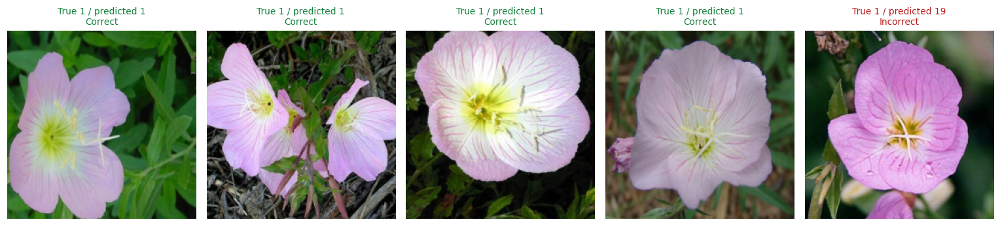

In [8]:
test_logits=[];test_labels=[]
with torch.no_grad():
 for images,labels in test_loader:
  test_logits.append(model(images.to(device)).cpu());test_labels.append(labels)
test_logits=torch.cat(test_logits);test_labels=torch.cat(test_labels);test_predictions=test_logits.argmax(1)
test_accuracy=accuracy_score(test_labels,test_predictions);test_macro_f1=f1_score(test_labels,test_predictions,average='macro')
print(f'Test accuracy: {test_accuracy:.2%}; macro F1: {test_macro_f1:.4f}')
correct_indices=torch.where(test_predictions==test_labels)[0][:4].tolist();wrong_indices=torch.where(test_predictions!=test_labels)[0][:1].tolist()
assert len(correct_indices)==4 and len(wrong_indices)==1
selected_indices=correct_indices+wrong_indices
selected_images=[test_full[i][0] for i in selected_indices];selected_labels=[int(test_labels[i]) for i in selected_indices];selected_preds=[int(test_predictions[i]) for i in selected_indices]
is_correct=[p==y for p,y in zip(selected_preds,selected_labels)];N=len(selected_indices)
test_batch=torch.stack(selected_images).to(device);labels_tensor=torch.tensor(selected_labels,device=device)
fig,axes=plt.subplots(1,N,figsize=(14,3.5))
for i,ax in enumerate(axes):
 ax.imshow(denormalize(selected_images[i]).permute(1,2,0));ax.set_title(f'True {selected_labels[i]+1} / predicted {selected_preds[i]+1}\n'+('Correct' if is_correct[i] else 'Incorrect'),color='#15803d' if is_correct[i] else '#b91c1c',fontsize=9);ax.axis('off')
plt.tight_layout();plt.show()

## RGB permutation and feature-channel ablation

RGB permutation swaps one entire channel between the five selected images and measures the change in mean true-class probability. It can create unnatural color combinations; negative values mean the perturbation raised the measured probability.

Intermediate-channel ablation zeros a feature channel rather than permuting it. I examine all 1,024 channels of inception5b. Because evaluation ends with global average pooling and a linear classifier, each channel's contribution can be removed directly from the logits. A forward-hook check verifies this calculation for one channel.

,channel,mean_probability_drop,repeat_std
0,Red,0.087147,0.054306
1,Green,0.046161,0.054155
2,Blue,0.174598,0.083975


,channel,mean_probability_drop
858,858,0.020583
128,128,0.017270
859,859,0.015453
853,853,0.013973
480,480,0.013208


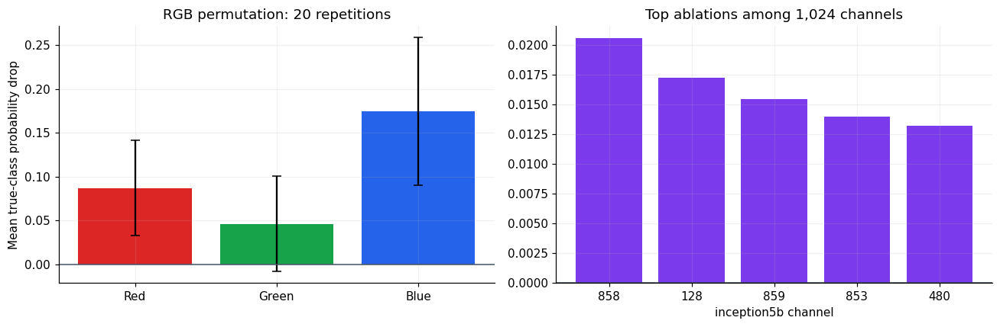

In [9]:
def compute_rgb_importance(model,images,labels,n_repeats=20):
 with torch.no_grad():
  base=F.softmax(model(images),dim=1).gather(1,labels[:,None]).mean().item()
  rows=[]
  for channel,name in enumerate(['Red','Green','Blue']):
   drops=[]
   for repeat in range(n_repeats):
    p=images.clone();p[:,channel]=images[torch.randperm(len(images),device=device),channel]
    prob=F.softmax(model(p),dim=1).gather(1,labels[:,None]).mean().item();drops.append(base-prob)
   rows.append({'channel':name,'mean_probability_drop':np.mean(drops),'repeat_std':np.std(drops,ddof=1)})
 return base,pd.DataFrame(rows)
baseline_conf,rgb_results=compute_rgb_importance(model,test_batch,labels_tensor)
activations={}
handle=model.inception5b.register_forward_hook(lambda module,inputs,output:activations.update(features=output.detach()))
with torch.no_grad():
 logits=model(test_batch);pooled=activations['features'].mean(dim=(2,3));handle.remove()
 assert torch.allclose(model.fc(pooled),logits,atol=1e-4)
 ablated=logits[:,None,:]-pooled[:,:,None]*model.fc.weight.T[None,:,:]
 base=logits.softmax(-1).gather(1,labels_tensor[:,None])
 probs=ablated.softmax(-1).gather(2,labels_tensor[:,None,None].expand(-1,pooled.shape[1],1)).squeeze(-1)
 channel_drops=(base-probs).mean(0).cpu().numpy()
 def zero_channel(module,inputs,output):
  altered=output.clone();altered[:,0]=0;return altered
 handle=model.inception5b.register_forward_hook(zero_channel);checked=model(test_batch).softmax(-1).gather(1,labels_tensor[:,None]).squeeze(1);handle.remove()
 assert torch.allclose(checked,probs[:,0],atol=1e-5)
feature_results=pd.DataFrame({'channel':np.arange(len(channel_drops)),'mean_probability_drop':channel_drops}).sort_values('mean_probability_drop',ascending=False)
display(rgb_results);display(feature_results.head())
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].bar(rgb_results.channel,rgb_results.mean_probability_drop,yerr=rgb_results.repeat_std,color=['#dc2626','#16a34a','#2563eb'],capsize=4);axes[0].set(title='RGB permutation: 20 repetitions',ylabel='Mean true-class probability drop')
top=feature_results.head();axes[1].bar(top.channel.astype(str),top.mean_probability_drop,color='#7c3aed');axes[1].set(title='Top ablations among 1,024 channels',xlabel='inception5b channel')
for ax in axes:ax.axhline(0,color='#475569',lw=1)
plt.tight_layout();plt.show()

## Occlusion at two spatial scales

I cover each image with 16 × 16 patches at stride 8, then 32 × 32 patches at stride 16. Each patch is filled with zero in normalized space, corresponding to the ImageNet mean color. Signed maps measure the predicted-class probability drop: positive values support that prediction; negative values oppose it. Overlapping patches are averaged. Both scales share a color range within each image.

Occlusion completed: {'example': 1, 'seconds_16': 1.1383958480000729, 'patches_16': 729, 'seconds_32': 0.29322858599994106, 'patches_32': 169}


Occlusion completed: {'example': 2, 'seconds_16': 1.0298793079998632, 'patches_16': 729, 'seconds_32': 0.24781917199993586, 'patches_32': 169}


Occlusion completed: {'example': 3, 'seconds_16': 1.0322119209999983, 'patches_16': 729, 'seconds_32': 0.24854842299987467, 'patches_32': 169}


Occlusion completed: {'example': 4, 'seconds_16': 1.0403041010001743, 'patches_16': 729, 'seconds_32': 0.2486618160000944, 'patches_32': 169}


Occlusion completed: {'example': 5, 'seconds_16': 1.0481832830000712, 'patches_16': 729, 'seconds_32': 0.24917756099989674, 'patches_32': 169}


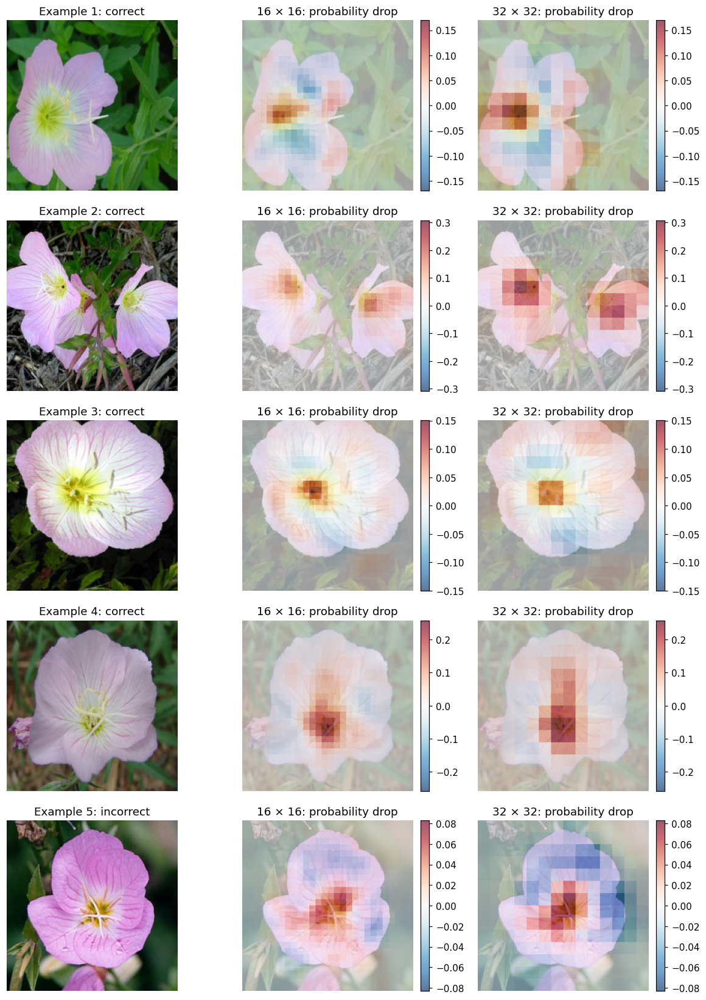

,example,seconds_16,patches_16,seconds_32,patches_32
0,1,1.138396,729,0.293229,169
1,2,1.029879,729,0.247819,169
2,3,1.032212,729,0.248548,169
3,4,1.040304,729,0.248662,169
4,5,1.048183,729,0.249178,169


In [10]:
def occlusion_sensitivity(model,image,target,patch_size,stride):
 coordinates=[(r,c) for r in range(0,224-patch_size+1,stride) for c in range(0,224-patch_size+1,stride)]
 heat=np.zeros((224,224),dtype=np.float32);counts=np.zeros_like(heat)
 with torch.no_grad():
  base=model(image[None].to(device)).softmax(-1)[0,target].item()
  for begin in range(0,len(coordinates),32):
   coords=coordinates[begin:begin+32];batch=image[None].repeat(len(coords),1,1,1)
   for j,(r,c) in enumerate(coords):batch[j,:,r:r+patch_size,c:c+patch_size]=0
   drops=base-model(batch.to(device)).softmax(-1)[:,target].cpu().numpy()
   for drop,(r,c) in zip(drops,coords):heat[r:r+patch_size,c:c+patch_size]+=drop;counts[r:r+patch_size,c:c+patch_size]+=1
 assert np.all(counts>0)
 return heat/counts,len(coordinates)
occ16=[];occ32=[];occlusion_times=[]
for i,(image,target) in enumerate(zip(selected_images,selected_preds)):
 row={'example':i+1}
 for patch,stride,dest in [(16,8,occ16),(32,16,occ32)]:
  torch.cuda.synchronize();start=time.perf_counter();heat,passes=occlusion_sensitivity(model,image,target,patch,stride);torch.cuda.synchronize();dest.append(heat);row[f'seconds_{patch}']=time.perf_counter()-start;row[f'patches_{patch}']=passes
 occlusion_times.append(row);print('Occlusion completed:',row,flush=True)
occlusion_times=pd.DataFrame(occlusion_times)
fig,axes=plt.subplots(N,3,figsize=(11,3*N))
for i in range(N):
 visual=denormalize(selected_images[i]).permute(1,2,0);limit=max(np.abs(occ16[i]).max(),np.abs(occ32[i]).max(),1e-8)
 axes[i,0].imshow(visual);axes[i,0].set_title(f'Example {i+1}: '+('correct' if is_correct[i] else 'incorrect'))
 for j,heat,patch in [(1,occ16[i],16),(2,occ32[i],32)]:
  axes[i,j].imshow(visual);im=axes[i,j].imshow(heat,cmap='RdBu_r',vmin=-limit,vmax=limit,alpha=.65);axes[i,j].set_title(f'{patch} × {patch}: probability drop');fig.colorbar(im,ax=axes[i,j],fraction=.046,pad=.04)
 for ax in axes[i]:ax.axis('off')
plt.tight_layout();plt.show()
display(occlusion_times)

## SHAP expected-gradient attributions

GradientExplainer uses 50 training images as background and 200 Monte Carlo samples per explained image. I explain only the highest-scoring output, verify that it is the predicted class, and retain signed logit attributions. This avoids unnecessarily explaining all 102 outputs. The channel-summed maps are approximate local explanations, not segmentation masks or proof of causal importance.

,example,logit_minus_background_mean,sum_attributions,approximation_residual
0,1,6.434239,5.766274,0.667965
1,2,7.017078,7.483617,-0.466540
2,3,7.286550,9.005820,-1.719269
3,4,6.806654,6.240205,0.566449
4,5,4.135089,4.067523,0.067566


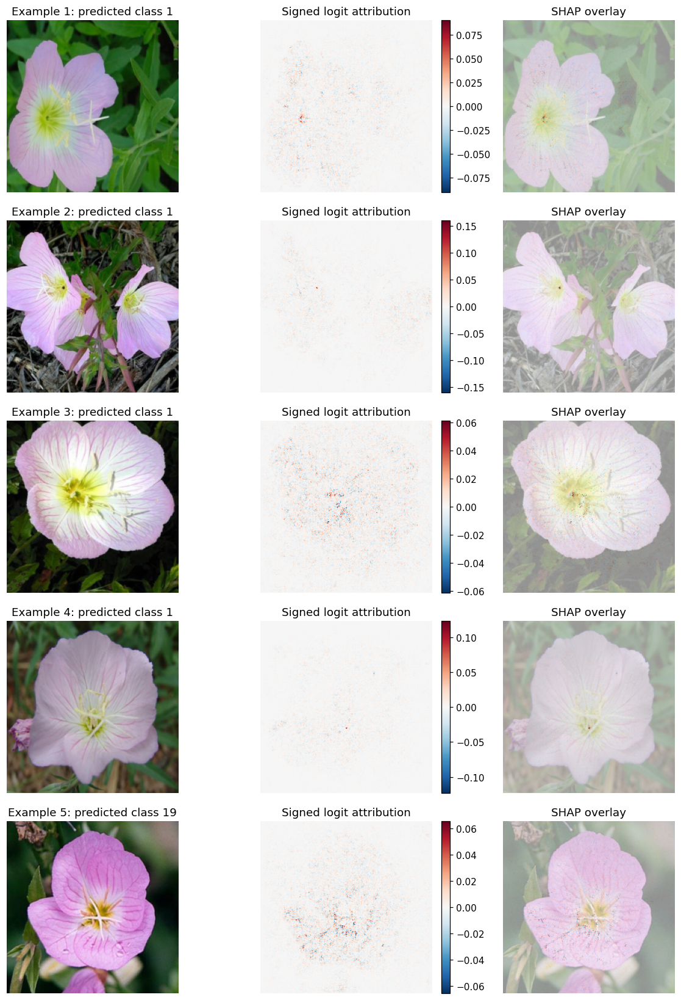

In [11]:
rng=np.random.default_rng(SEED);background_indices=rng.choice(len(train_clean),50,replace=False)
background=torch.stack([train_clean[int(i)][0] for i in background_indices]).to(device)
explainer=shap.GradientExplainer(model,background,batch_size=16)
values,output_indices=explainer.shap_values(test_batch,nsamples=200,ranked_outputs=1,rseed=SEED)
assert np.array_equal(output_indices.cpu().numpy().reshape(-1),np.array(selected_preds))
if isinstance(values,list):attributions=np.asarray(values[0])
else:
 attributions=np.asarray(values)
 if attributions.ndim==5:attributions=attributions[...,0]
assert attributions.shape==(N,3,224,224),attributions.shape
assert np.all(np.isfinite(attributions))
shap_maps=attributions.sum(axis=1)
with torch.no_grad():background_logits=model(background).mean(0).cpu().numpy()
shap_checks=[]
for i,target in enumerate(selected_preds):
 difference=float(test_logits[selected_indices[i],target])-float(background_logits[target]);total=float(attributions[i].sum())
 shap_checks.append({'example':i+1,'logit_minus_background_mean':difference,'sum_attributions':total,'approximation_residual':difference-total})
shap_checks=pd.DataFrame(shap_checks);display(shap_checks)
fig,axes=plt.subplots(N,3,figsize=(11,3*N))
for i in range(N):
 visual=denormalize(selected_images[i]).permute(1,2,0);limit=max(np.abs(shap_maps[i]).max(),1e-8)
 axes[i,0].imshow(visual);axes[i,0].set_title(f'Example {i+1}: predicted class {selected_preds[i]+1}')
 im=axes[i,1].imshow(shap_maps[i],cmap='RdBu_r',vmin=-limit,vmax=limit);axes[i,1].set_title('Signed logit attribution');fig.colorbar(im,ax=axes[i,1],fraction=.046,pad=.04)
 axes[i,2].imshow(visual);axes[i,2].imshow(shap_maps[i],cmap='RdBu_r',vmin=-limit,vmax=limit,alpha=.6);axes[i,2].set_title('SHAP overlay')
 for ax in axes[i]:ax.axis('off')
plt.tight_layout();plt.show()

## Comparing the explanation methods

Occlusion measures a probability change after removing a region; SHAP attributes the predicted logit relative to a background distribution. Their magnitudes have different units. Signed spatial rank correlations below compare ordering, not absolute scale. Neighboring pixels are dependent, so I do not interpret pixel-wise p-values as statistical evidence. The five examples were selected for illustration, not a general benchmark.

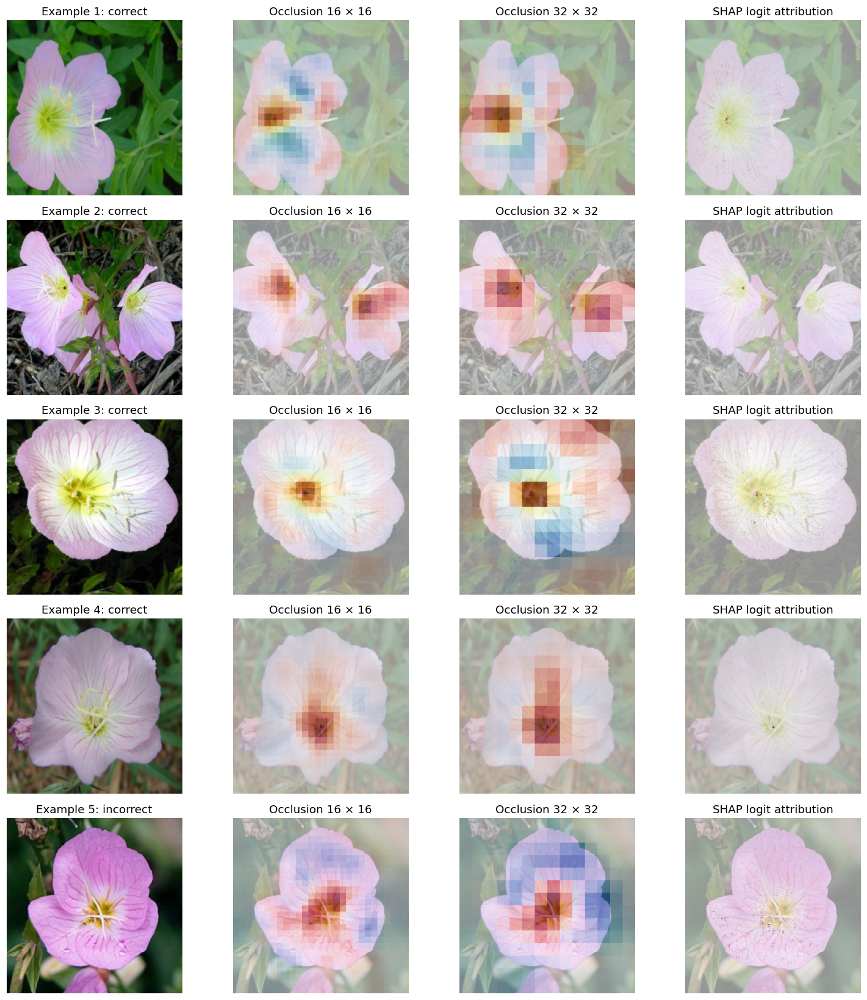

,example,correct,spearman_signed_occlusion_shap,spearman_occlusion_scales
0,1,True,-0.002419,0.692526
1,2,True,0.030241,0.741983
2,3,True,0.006571,0.501092
3,4,True,0.020151,0.678173
4,5,False,0.001799,0.691984


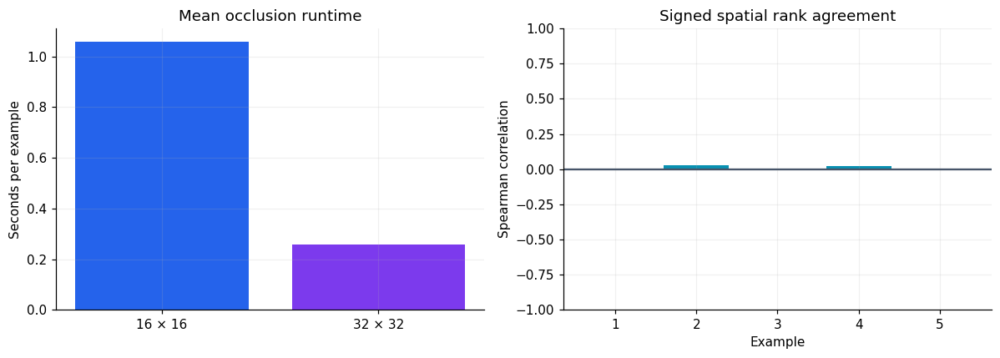

In [12]:
comparison=[]
fig,axes=plt.subplots(N,4,figsize=(14,3*N))
for i in range(N):
 visual=denormalize(selected_images[i]).permute(1,2,0)
 axes[i,0].imshow(visual);axes[i,0].set_title(f'Example {i+1}: '+('correct' if is_correct[i] else 'incorrect'))
 for j,heat,title in [(1,occ16[i],'Occlusion 16 × 16'),(2,occ32[i],'Occlusion 32 × 32'),(3,shap_maps[i],'SHAP logit attribution')]:
  limit=max(np.abs(heat).max(),1e-8);axes[i,j].imshow(visual);axes[i,j].imshow(heat,cmap='RdBu_r',vmin=-limit,vmax=limit,alpha=.6);axes[i,j].set_title(title)
 for ax in axes[i]:ax.axis('off')
 comparison.append({'example':i+1,'correct':bool(is_correct[i]),'spearman_signed_occlusion_shap':float(spearmanr(occ16[i].ravel(),shap_maps[i].ravel()).statistic),'spearman_occlusion_scales':float(spearmanr(occ16[i].ravel(),occ32[i].ravel()).statistic)})
plt.tight_layout();plt.show()
comparison=pd.DataFrame(comparison);display(comparison)
fig,axes=plt.subplots(1,2,figsize=(11,4))
axes[0].bar(['16 × 16','32 × 32'],[occlusion_times.seconds_16.mean(),occlusion_times.seconds_32.mean()],color=['#2563eb','#7c3aed']);axes[0].set(title='Mean occlusion runtime',ylabel='Seconds per example')
axes[1].bar(comparison.example.astype(str),comparison.spearman_signed_occlusion_shap,color='#0891b2');axes[1].axhline(0,color='#475569');axes[1].set(title='Signed spatial rank agreement',xlabel='Example',ylabel='Spearman correlation',ylim=(-1,1))
plt.tight_layout();plt.show()
results={'test_accuracy':float(test_accuracy),'test_macro_f1':float(test_macro_f1),'best_validation_epoch':int(best_epoch),'best_validation_loss':float(best_loss),'training_seconds':training_seconds,'train_images':1020,'validation_images':1020,'test_images':6149,'epochs':30,'selected_indices':selected_indices,'selected_true_classes':selected_labels,'selected_predicted_classes':selected_preds,'rgb_permutation':rgb_results.to_dict('records'),'explanation_comparison':comparison.to_dict('records'),'shap_background_images':50,'shap_samples':200}
Path('results.json').write_text(json.dumps(results,indent=2));history.to_csv('training_history.csv',index=False);feature_results.to_csv('feature_ablation.csv',index=False);shap_checks.to_csv('shap_additivity.csv',index=False)

## What I learned

Checkpoint selection needs a validation partition even when the goal is explanation rather than accuracy. Permuting input channels, removing intermediate channels, masking spatial patches, and attributing logits answer different questions. Signed maps preserve both supporting and opposing contributions. Explanations depend on the target class, background, patch size, and approximation budget; visual agreement alone does not establish faithfulness.

References: [Oxford Flowers102](https://www.robots.ox.ac.uk/~vgg/data/flowers/102/) · [SHAP GradientExplainer](https://shap.readthedocs.io/en/stable/generated/shap.GradientExplainer.html) · [torchvision GoogLeNet](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.googlenet.html)

## Measured findings

The validation-selected checkpoint from epoch **30** achieved **83.95%** accuracy and **0.8276** macro F1 on all 6,149 test images. Explanation comparisons use five selected examples and must not be generalized to the full dataset.

All five selected images belong to the same true flower class (class 1 in the plots), so this is a within-class illustration. Blue-channel permutation produced the largest mean true-class probability drop (0.1746) on these examples. Signed occlusion–SHAP spatial rank agreement was weak (mean 0.0113), while the two occlusion scales agreed more strongly (mean 0.6612). The largest SHAP additivity approximation residual was 1.72 logit units with 200 samples; these maps remain approximate.